# Visualize heatmap models

Pick any architecture from `ARCH_REGISTRY` (RGB CNN, frame-diff CNN, event-frame CNN, …).
Loads the matching val batch + checkpoint, shows a modality-aware preview + GT / pred heatmaps + overlay.

Models output **heatmap logits + presence**. Decode is argmax gated by `sigmoid(presence)`. Measurement noise `r` comes from peak sharpness (soft spatial std).

Set `USE_CROP = True` to sample jittered bucket crops: each row shows the **crop**, **in_crop** / presence, GT / pred heatmaps, and gated overlay.

New models work automatically once registered in `horus.eval.bench.ARCH_REGISTRY` with a `checkpoints/<arch>.pt` file.

In [3]:
import matplotlib.pyplot as plt

import numpy as np

import torch



from horus.config import load_config, repo_root

from horus.data.dataset import build_dataloader

from horus.eval import ARCH_REGISTRY, load_model

from horus.eval.metrics import input_channels

from horus.models import heatmap_to_coords, soft_heatmap_spatial_std, unpack_model_output

from horus.track.loop import detection_to_measurement



# =============================================================================

# Controls — edit, then re-run this cell and below

# =============================================================================

ARCH = "event_frame_cnn"  # rgb_cnn | diff_cnn | event_frame_cnn | event_frame_snn | …

SPLIT = "val"

BATCH_SIZE = 4

USE_CROP = True  # True → jittered bucket crops (+ negatives); False → full frame

SEED = 0  # crop RNG; None = nondeterministic

CKPT_NAME = None  # e.g. "rgb_cnn.pt"; None → checkpoints/<ARCH>.pt

# =============================================================================



ROOT = repo_root()

cfg = load_config()

cfg.setdefault("crop", {})["enabled"] = bool(USE_CROP)

dcfg = cfg.get("detector") or {}

PRESENCE_THRESH = float(dcfg.get("presence_thresh", 0.5))



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")



if ARCH not in ARCH_REGISTRY:

    raise KeyError(f"Unknown ARCH={ARCH!r}. Known: {sorted(ARCH_REGISTRY)}")

_, modality = ARCH_REGISTRY[ARCH]

ckpt_path = ROOT / "checkpoints" / (CKPT_NAME or f"{ARCH}.pt")

if not ckpt_path.is_file():

    raise FileNotFoundError(f"Missing checkpoint: {ckpt_path}")



model = load_model(ARCH, ckpt_path, device)

ckpt_meta = torch.load(ckpt_path, map_location="cpu", weights_only=True)

has_presence = bool(ckpt_meta.get("predict_presence", False)) or any(

    str(k).startswith("presence_head") for k in ckpt_meta.get("model", {})

)

print(

    f"arch={ARCH} modality={modality} in_ch={input_channels(modality, cfg)} "

    f"crop={USE_CROP} presence_head={has_presence} thresh={PRESENCE_THRESH} "

    f"epoch={ckpt_meta.get('epoch')} val_px={ckpt_meta.get('val_px')} device={device}"

)

print(f"ckpt={ckpt_path.name}  registered: {sorted(ARCH_REGISTRY)}")



loader = build_dataloader(

    cfg,

    SPLIT,

    modality,

    batch_size=BATCH_SIZE,

    num_workers=0,

    shuffle=False,

    seed=SEED,

)

batch = next(iter(loader))

with torch.no_grad():

    out = model(batch["input"].to(device))

heat_logits, presence = unpack_model_output(out)

heat_logits = heat_logits.cpu()

presence = None if presence is None else presence.cpu()

pred = torch.sigmoid(heat_logits)

gt, coords = batch["heatmap"], batch["coords"]

pred_xy = heatmap_to_coords(heat_logits)

in_crop = batch.get("in_crop", batch["visible"])

crop_origin = batch.get("crop_origin")

crop_size = batch.get("crop_size")

r_meas = soft_heatmap_spatial_std(heat_logits)



arch=event_frame_cnn modality=event_frame in_ch=6 crop=True presence_head=True thresh=0.5 epoch=4 val_px=3.7395069668819376 device=cuda
ckpt=event_frame_cnn.pt  registered: ['diff_cnn', 'event_frame_cnn', 'event_frame_snn', 'rgb_cnn']


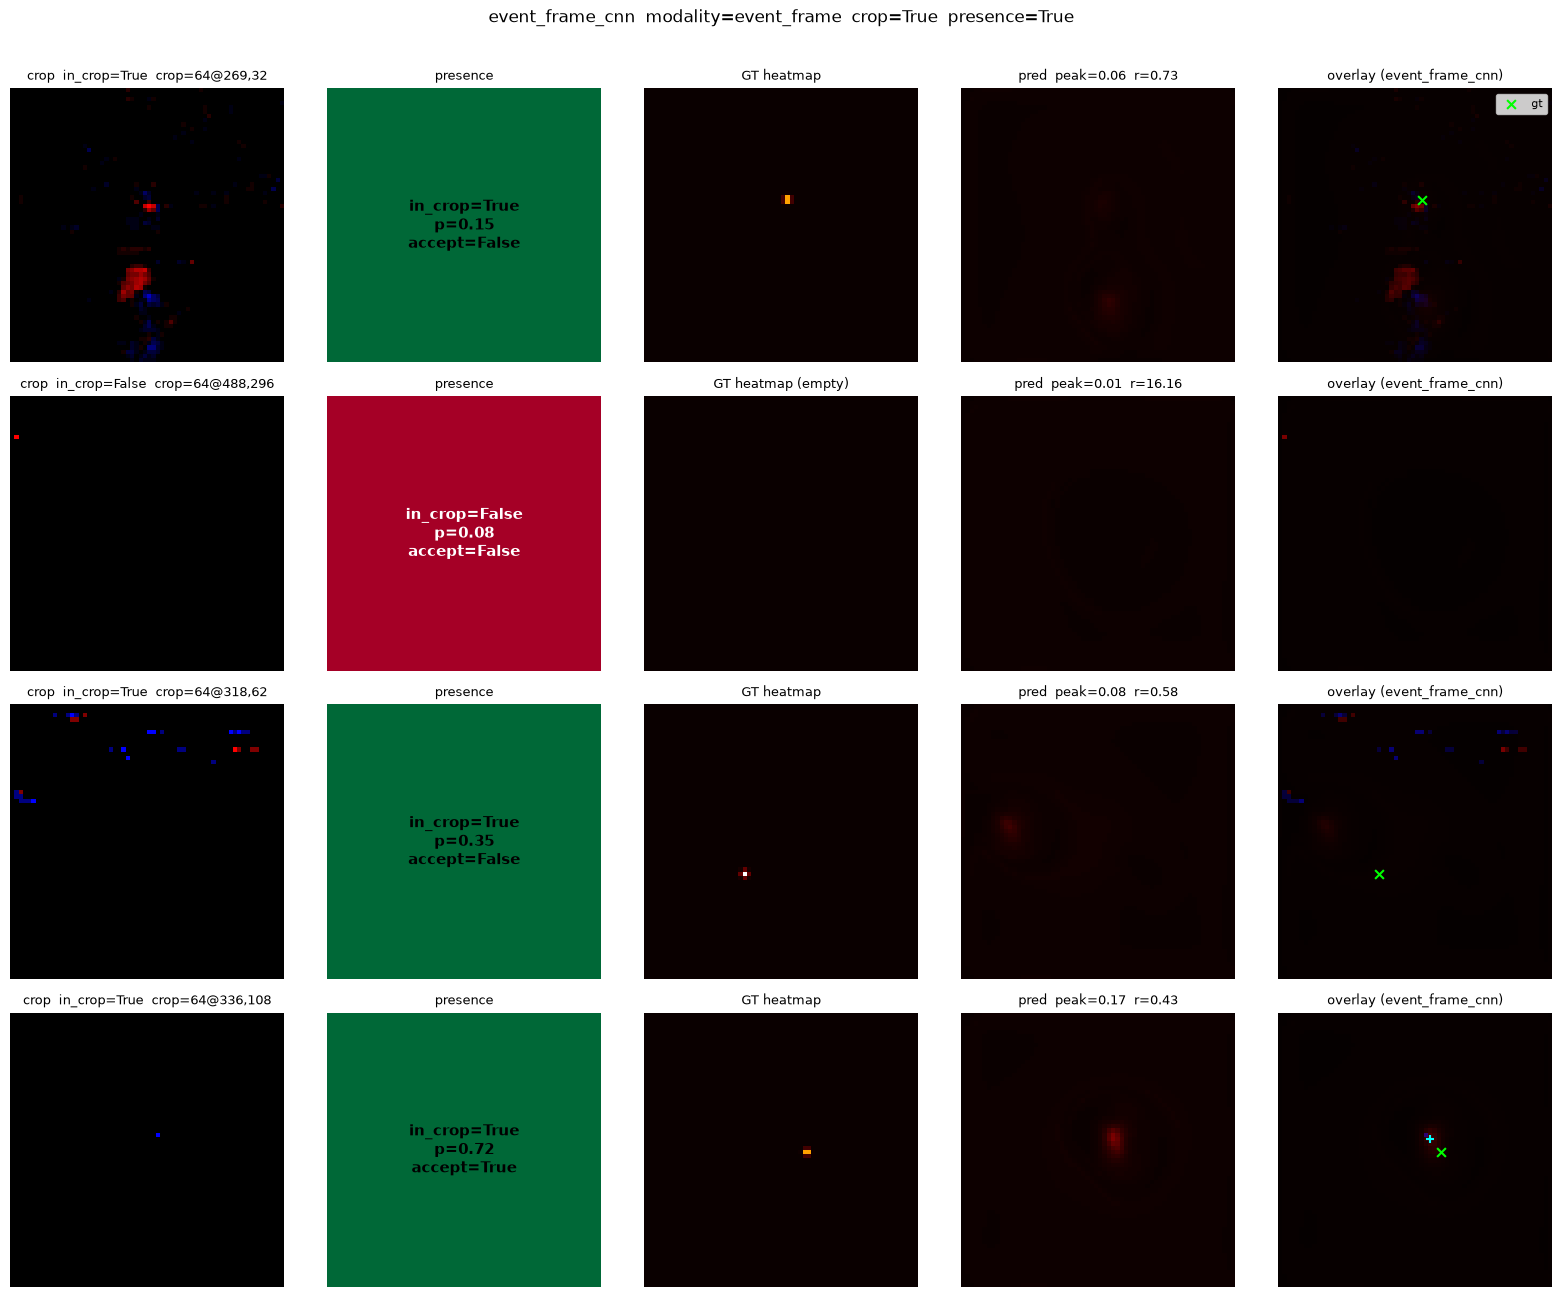

 i  game/clip           frame         in_crop       p  accept    peak       r           gt_xy         pred_xy
 0  game8/Clip1         0002.jpg         True    0.15   False   0.056    0.73         (33,26)  (34,49)
 1  game8/Clip1         0005.jpg        False    0.08   False   0.012   16.16               —  (26,46)
 2  game8/Clip1         0008.jpg         True    0.35   False   0.079    0.58         (23,39)  (11,28)
 3  game8/Clip1         0011.jpg         True    0.72    True   0.171    0.43         (38,32)  (35,29)


In [4]:
def preview_input(chw: torch.Tensor, modality: str, cfg: dict) -> np.ndarray:

    """Turn a stacked model input (C, H, W) into an HxWx3 float image for imshow."""

    x = chw.detach().float().cpu().numpy()

    _, h, w = x.shape



    if modality == "rgb":

        frame = x[-3:].transpose(1, 2, 0)

        return np.clip(frame, 0, 1)



    if modality == "diff":

        g = x[-1]

        g = g / (g.max() + 1e-8)

        return np.stack([g, g, g], axis=-1)



    if modality == "event_frame":

        pos, neg = x[-2], x[-1]

        scale = max(float(pos.max()), float(neg.max()), 1e-8)

        rgb = np.zeros((h, w, 3), dtype=np.float32)

        rgb[..., 0] = pos / scale

        rgb[..., 2] = neg / scale

        return np.clip(rgb, 0, 1)



    if modality == "voxel":

        bins = int(cfg.get("events", {}).get("voxel", {}).get("num_bins", 5))

        last = x[-bins:]

        g = np.abs(last).sum(axis=0)

        g = g / (g.max() + 1e-8)

        return np.stack([g, g, g], axis=-1)



    g = np.abs(x).mean(axis=0)

    g = g / (g.max() + 1e-8)

    return np.stack([g, g, g], axis=-1)





n = pred.shape[0]

ncols = 5 if USE_CROP else 4

fig, axes = plt.subplots(n, ncols, figsize=(3.2 * ncols, 3.2 * n))

if n == 1:

    axes = np.asarray(axes).reshape(1, -1)



for i in range(n):

    frame = preview_input(batch["input"][i], modality, cfg)

    g, p = gt[i, 0].numpy(), pred[i, 0].numpy()

    gx, gy = coords[i].tolist()

    px, py = pred_xy[i].tolist()

    ball_in = bool(float(in_crop[i].item()) > 0.5)

    peak = float(p.max())

    p_pres = float(torch.sigmoid(presence[i]).item()) if presence is not None else float("nan")

    accepted = (presence is None) or (p_pres >= PRESENCE_THRESH)

    r = float(r_meas[i].item())



    crop_str = ""

    if USE_CROP and crop_origin is not None and crop_size is not None:

        x0, y0 = int(crop_origin[i, 0]), int(crop_origin[i, 1])

        sz = int(crop_size[i].item()) if torch.is_tensor(crop_size[i]) else int(crop_size[i])

        crop_str = f"  crop={sz}@{x0},{y0}"



    axes[i, 0].imshow(frame)

    title0 = f"{batch['game'][i]}/{batch['clip'][i]} {batch['frame'][i]}"

    if USE_CROP:

        title0 = f"crop  in_crop={ball_in}{crop_str}"

    axes[i, 0].set_title(title0, fontsize=9)



    if USE_CROP:

        axes[i, 1].imshow(

            np.full_like(frame[..., 0], 1.0 if ball_in else 0.0),

            cmap="RdYlGn",

            vmin=0,

            vmax=1,

        )

        axes[i, 1].text(

            0.5, 0.5,

            f"in_crop={ball_in}\np={p_pres:.2f}\naccept={accepted}",

            ha="center", va="center", fontsize=11, fontweight="bold",

            color="black" if ball_in else "white",

            transform=axes[i, 1].transAxes,

        )

        axes[i, 1].set_title("presence", fontsize=9)

        gt_ax, pred_ax, overlay_ax = axes[i, 2], axes[i, 3], axes[i, 4]

    else:

        gt_ax, pred_ax, overlay_ax = axes[i, 1], axes[i, 2], axes[i, 3]



    gt_ax.imshow(g, cmap="hot", vmin=0, vmax=1)

    gt_ax.set_title("GT heatmap" + (" (empty)" if not ball_in else ""), fontsize=9)



    pred_ax.imshow(p, cmap="hot", vmin=0, vmax=1)

    pred_ax.set_title(f"pred  peak={peak:.2f}  r={r:.2f}", fontsize=9)



    overlay_ax.imshow(frame)

    overlay_ax.imshow(p, cmap="hot", alpha=0.55, vmin=0, vmax=1)

    if ball_in:

        overlay_ax.scatter([gx], [gy], c="lime", s=40, marker="x", label="gt")

    if accepted:

        overlay_ax.scatter([px], [py], c="cyan", s=40, marker="+", label="pred")

    else:

        overlay_ax.set_xlabel("miss (presence)", fontsize=8)

    overlay_ax.set_title(f"overlay ({ARCH})", fontsize=9)

    if i == 0:

        overlay_ax.legend(loc="upper right", fontsize=8)



for ax in axes.ravel():

    ax.axis("off")

plt.suptitle(

    f"{ARCH}  modality={modality}  crop={USE_CROP}  presence={has_presence}",

    y=1.01,

)

plt.tight_layout()

plt.show()



print(

    f"{'i':>2}  {'game/clip':<18}  {'frame':<12}  {'in_crop':>7}  "

    f"{'p':>6}  {'accept':>6}  {'peak':>6}  {'r':>6}  {'gt_xy':>14}  {'pred_xy':>14}"

)

for i in range(n):

    ball_in = bool(float(in_crop[i].item()) > 0.5)

    peak = float(pred[i, 0].max().item())

    p_pres = float(torch.sigmoid(presence[i]).item()) if presence is not None else float("nan")

    accepted = (presence is None) or (p_pres >= PRESENCE_THRESH)

    r = float(r_meas[i].item())

    gx, gy = coords[i].tolist()

    px, py = pred_xy[i].tolist()

    gt_s = f"({gx:.0f},{gy:.0f})" if ball_in else "—"

    print(

        f"{i:2d}  {batch['game'][i]}/{batch['clip'][i]:<12}  "

        f"{str(batch['frame'][i]):<12}  "

        f"{str(ball_in):>7}  {p_pres:6.2f}  {str(accepted):>6}  "

        f"{peak:6.3f}  {r:6.2f}  {gt_s:>14}  ({px:.0f},{py:.0f})"

    )

